# Trayectorias · movimientos con condiciones de frontera

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. Una postura inicial y una final no definen el movimiento

También se necesita duración y una ley temporal. Se emplea el ejemplo del informe: 3 s desde `[30,40,-50]` hasta `[-20,20,-70]` grados. Se interpola en espacio articular; el efector no tiene por qué seguir una recta.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

q_initial = np.deg2rad([30, 40, -50])
q_final = np.deg2rad([-20, 20, -70])
duration = 3.0
t = np.linspace(0, duration, 301)
u = t / duration
delta = q_final - q_initial

## 2. Elegir una función de progreso

Se escribe $q(t)=q_i+(q_f-q_i)s(u)$, con $u=t/T$. Las condiciones son $s(0)=0$, $s(1)=1$ y velocidades nulas en extremos.

Cúbica: $s=3u^2-2u^3$. Quíntica: $s=10u^3-15u^4+6u^5$, que además tiene aceleraciones nulas en extremos. Las derivadas respecto al tiempo incluyen factores $1/T$ y $1/T^2$.

In [2]:
s3 = 3*u**2 - 2*u**3
ds3 = (6*u - 6*u**2) / duration
dds3 = (6 - 12*u) / duration**2
s5 = 10*u**3 - 15*u**4 + 6*u**5
ds5 = (30*u**2 - 60*u**3 + 30*u**4) / duration
dds5 = (60*u - 180*u**2 + 120*u**3) / duration**2

# [:, None] convierte un vector de N tiempos en una columna N×1.
# Multiplicarlo por delta (3 componentes) produce N×3 valores articulares.
q_cubic = q_initial + s3[:, None] * delta
v_cubic = ds3[:, None] * delta
a_cubic = dds3[:, None] * delta
q_quintic = q_initial + s5[:, None] * delta
v_quintic = ds5[:, None] * delta
a_quintic = dds5[:, None] * delta

## 3. Comprobar extremos y comparar las tres articulaciones

`[0,-1]` selecciona la primera y la última fila. La aceleración de la cúbica es finita pero no nula en esos extremos; si antes y después el robot está quieto, hay un salto de aceleración.

Máxima aceleración en extremos, cúbica: 0.581776417331443
Máxima aceleración en extremos, quíntica: 0.0


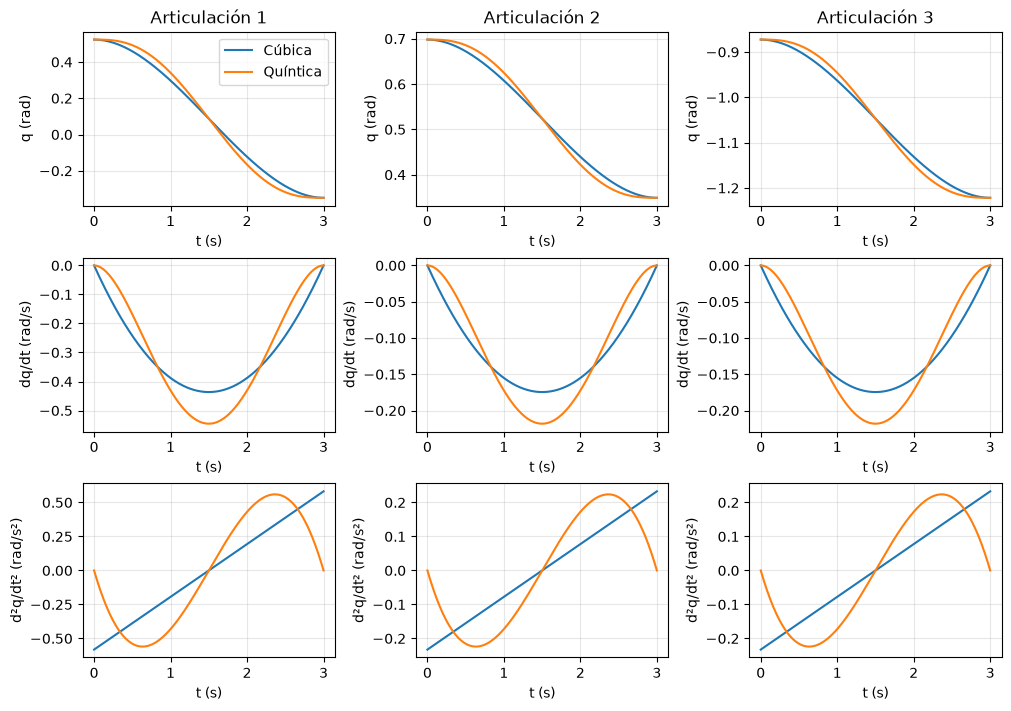

In [3]:
assert np.allclose(q_cubic[[0, -1]], [q_initial, q_final])
assert np.allclose(q_quintic[[0, -1]], [q_initial, q_final])
assert np.allclose(v_cubic[[0, -1]], 0)
assert np.allclose(v_quintic[[0, -1]], 0)
assert np.allclose(a_quintic[[0, -1]], 0)
print("Máxima aceleración en extremos, cúbica:", np.abs(a_cubic[[0, -1]]).max())
print("Máxima aceleración en extremos, quíntica:", np.abs(a_quintic[[0, -1]]).max())

fig, axes = plt.subplots(3, 3, figsize=(10, 7), layout="constrained")
for row, (cubic, quintic, label) in enumerate([
    (q_cubic, q_quintic, "q (rad)"), (v_cubic, v_quintic, "dq/dt (rad/s)"),
    (a_cubic, a_quintic, "d²q/dt² (rad/s²)"),
]):
    for joint in range(3):
        ax = axes[row, joint]
        ax.plot(t, cubic[:, joint], label="Cúbica")
        ax.plot(t, quintic[:, joint], label="Quíntica")
        ax.set(xlabel="t (s)", ylabel=label)
        ax.grid(alpha=0.3)
for joint in range(3):
    axes[0, joint].set_title(f"Articulación {joint+1}")
axes[0, 0].legend()
plt.show()

## 4. Pasar del espacio articular al cartesiano

La cinemática directa se evalúa en cada fila. En este ejemplo cúbica y quíntica recorren el mismo segmento en espacio articular con distinta velocidad; por ello describen la misma curva geométrica del efector, aunque la parametrización temporal cambia.

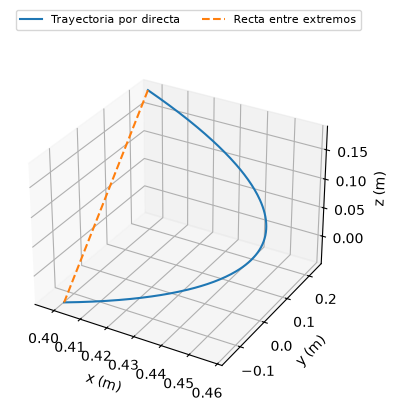

In [4]:
path = np.array([position(q) for q in q_quintic])
fig = plt.figure(figsize=(6, 4), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
ax.plot(*path.T, label="Trayectoria por directa")
ax.plot(*path[[0, -1]].T, "--", label="Recta entre extremos")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.15), ncol=2, fontsize=8)
plt.show()

## Lectura y ejercicio

En el ejemplo la aceleración máxima de extremo de la cúbica es aproximadamente 0.582 rad/s²; la quíntica da cero. Duplicar la duración reduce las velocidades a la mitad y las aceleraciones a la cuarta parte para el mismo progreso normalizado.

Suavidad temporal no garantiza ausencia de singularidades, colisiones o velocidades admisibles. **Siguiente:** usar una referencia en el [control cinemático](../control/README.md).